<div style="background:#1F4E9C;color:white;padding:18px 22px;border-radius:10px;border-bottom:5px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/assets/logo_transparent.png" alt="Algo Professor" style="float:right;height:74px;background:white;border-radius:8px;padding:4px 8px">
<div style="font-size:13px;letter-spacing:2px;color:#F6EBC4">ALGOPROFESSOR · AI SCIENTIST HANDS-ON · SUNDAY 6</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Production, Responsible AI & Capstone</div>
<div style="font-size:15px;margin-top:6px">Hours 26–30 · 2 h hands-on teaching + 3 h real-time project work · GitHub submission by 18:00</div>
</div>

| Hour | Mode | Focus | Dataset |
|---|---|---|---|
| 26 | TEACH | MLOps: FastAPI service, tests, Docker, CI/CD, model registry, drift monitoring | IBM Telco + California Housing (drift) |
| 27 | TEACH | Responsible AI: fairness metrics & mitigation, red-teaming, AI law basics | UCI Adult + TruthfulQA |
| 28 | BUILD | Capstone hardening: automated readiness audit | Your capstone repo |
| 29 | BUILD | Demo Day: 7-minute pitch built from your real results | Your capstone results |
| 30 | BUILD | Career Lab: mock-interview drawer, skills radar, 90-day plan | Interview question bank |

> In class the drift demo uses NYC TLC taxi trips month by month. Here we create a real, measurable shift from
> California Housing (coastal districts as "last month", inland districts as "this month").

In [1]:
# ---------- Setup (run once) ----------
import os, pathlib, urllib.request, warnings, time, json, random
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Data cache lives at the repository root (data/ is git-ignored); figures go next to the notes.
DATA = pathlib.Path(os.environ.get("AP_DATA", "../../data")); DATA.mkdir(parents=True, exist_ok=True)
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)

def fetch(url, name):
    """Download a file once into the shared data cache and return its path."""
    p = DATA / name
    if not p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, p)
    return p

# AlgoProfessor colour palette
NAVY, GOLD, GREEN, PURPLE = "#0B1F3A", "#C9A227", "#1E7B5A", "#6A3D9A"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
                     "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=[NAVY, GOLD, GREEN, PURPLE, "#A4243B", "#C25E00"])})
print("Setup complete. Data cache:", DATA.resolve())

Setup complete. Data cache: /home/claude/build/data


In [2]:
import joblib, subprocess, sys, textwrap
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, root_mean_squared_error
PROJ = pathlib.Path("capstone_demo"); (PROJ / "app").mkdir(parents=True, exist_ok=True); (PROJ / "tests").mkdir(exist_ok=True)
(PROJ / ".github" / "workflows").mkdir(parents=True, exist_ok=True); (PROJ / "registry").mkdir(exist_ok=True)

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 26 — MLOps: package, test, containerise, automate, monitor

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">IBM Telco (service) + California Housing (drift)</span>
**Skills:** <span style="color:#6A3D9A">FastAPI, pytest, Docker, GitHub Actions, model registry, drift detection</span>

### 26.1 Train and register a model version

In [3]:
telco = pd.read_csv(fetch("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv", "telco_churn.csv"))
telco["TotalCharges"] = pd.to_numeric(telco.TotalCharges, errors="coerce")
FEATURES = ["tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport"]
X, y = telco[FEATURES], (telco.Churn == "Yes").astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
num, cat = FEATURES[:3], FEATURES[3:]
model = Pipeline([("prep", ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
                                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
                  ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(Xtr, ytr)
auc = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])

def register(model, name, metrics):
    """A tiny file-based model registry: every version gets its artefact + a metadata card. (MLflow Model Registry does the same at scale.)"""
    versions = sorted(int(p.name[1:]) for p in (PROJ / "registry").glob("v*")) or [0]
    v = versions[-1] + 1; d = PROJ / "registry" / f"v{v}"; d.mkdir()
    joblib.dump(model, d / "model.joblib")
    meta = {"name": name, "version": v, "features": FEATURES, "metrics": metrics, "created": time.strftime("%Y-%m-%d %H:%M"), "stage": "staging"}
    (d / "meta.json").write_text(json.dumps(meta, indent=1)); return meta
meta = register(model, "churn-logreg", {"roc_auc": round(auc, 4)}); print(json.dumps(meta, indent=1))

{
 "name": "churn-logreg",
 "version": 1,
 "features": [
  "tenure",
  "MonthlyCharges",
  "TotalCharges",
  "Contract",
  "InternetService",
  "PaymentMethod",
  "OnlineSecurity",
  "TechSupport"
 ],
 "metrics": {
  "roc_auc": 0.8438
 },
 "created": "2026-11-25 13:00",
 "stage": "staging"
}


### 26.2 The service, its tests, the container and the CI pipeline

In [4]:
(PROJ / "app" / "__init__.py").write_text("")
(PROJ / "app" / "main.py").write_text(textwrap.dedent('''
    import json, pathlib, joblib, pandas as pd
    from fastapi import FastAPI, HTTPException
    from pydantic import BaseModel, Field

    REG = pathlib.Path(__file__).resolve().parents[1] / "registry"
    VERSION = sorted(REG.glob("v*"), key=lambda p: int(p.name[1:]))[-1]
    MODEL, META = joblib.load(VERSION / "model.joblib"), json.loads((VERSION / "meta.json").read_text())
    app = FastAPI(title="Churn Intelligence API", version=str(META["version"]))

    class Customer(BaseModel):
        tenure: int = Field(ge=0, le=120)
        MonthlyCharges: float = Field(gt=0)
        TotalCharges: float | None = None
        Contract: str
        InternetService: str
        PaymentMethod: str
        OnlineSecurity: str
        TechSupport: str

    @app.get("/health")
    def health(): return {"status": "ok", "model_version": META["version"]}

    @app.post("/predict")
    def predict(c: Customer):
        if c.Contract not in {"Month-to-month", "One year", "Two year"}:
            raise HTTPException(422, "unknown contract type")
        p = float(MODEL.predict_proba(pd.DataFrame([c.model_dump()]))[0, 1])
        return {"churn_probability": round(p, 4), "risk": "high" if p >= 0.5 else "low", "model_version": META["version"]}
'''))
(PROJ / "tests" / "test_api.py").write_text(textwrap.dedent('''
    from fastapi.testclient import TestClient
    from app.main import app
    client = TestClient(app)
    GOOD = {"tenure": 2, "MonthlyCharges": 95.0, "TotalCharges": 190.0, "Contract": "Month-to-month",
            "InternetService": "Fiber optic", "PaymentMethod": "Electronic check", "OnlineSecurity": "No", "TechSupport": "No"}

    def test_health():
        assert client.get("/health").json()["status"] == "ok"

    def test_high_risk_customer():
        r = client.post("/predict", json=GOOD); assert r.status_code == 200 and r.json()["risk"] == "high"

    def test_loyal_customer_is_lower_risk():
        loyal = {**GOOD, "tenure": 60, "Contract": "Two year", "OnlineSecurity": "Yes", "TechSupport": "Yes", "TotalCharges": 5000.0}
        assert client.post("/predict", json=loyal).json()["churn_probability"] < client.post("/predict", json=GOOD).json()["churn_probability"]

    def test_rejects_bad_input():
        assert client.post("/predict", json={**GOOD, "tenure": -5}).status_code == 422
        assert client.post("/predict", json={**GOOD, "Contract": "Lifetime"}).status_code == 422
'''))
(PROJ / "requirements.txt").write_text("fastapi\nuvicorn\npandas\nscikit-learn\njoblib\npytest\nhttpx\n")
(PROJ / "Dockerfile").write_text(textwrap.dedent('''
    FROM python:3.12-slim
    WORKDIR /srv
    COPY requirements.txt .
    RUN pip install --no-cache-dir -r requirements.txt
    COPY app ./app
    COPY registry ./registry
    USER 1000
    EXPOSE 8000
    CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]
'''))
(PROJ / ".github" / "workflows" / "ci.yml").write_text(textwrap.dedent('''
    name: ci
    on: [push, pull_request]
    jobs:
      test-and-build:
        runs-on: ubuntu-latest
        steps:
          - uses: actions/checkout@v4
          - uses: actions/setup-python@v5
            with: {python-version: "3.12"}
          - run: pip install -r requirements.txt
          - run: pytest -q
          - run: docker build -t churn-api:${{ github.sha }} .
'''))
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], cwd=PROJ, capture_output=True, text=True)
print(r.stdout[-600:])
print("files:", sorted(str(p.relative_to(PROJ)) for p in PROJ.rglob("*") if p.is_file() and "__pycache__" not in str(p) and ".pytest_cache" not in str(p)))

....                                                                     [100%]
4 passed in 1.64s

files: ['.github/workflows/ci.yml', 'Dockerfile', 'app/__init__.py', 'app/main.py', 'registry/v1/meta.json', 'registry/v1/model.joblib', 'requirements.txt', 'tests/test_api.py']


Run locally: `uvicorn app.main:app --reload` · Container: `docker build -t churn-api . && docker run -p 8000:8000 churn-api` ·
CI: push to GitHub and the workflow runs the tests and builds the image on every commit.

### 26.3 Drift monitoring: is today's data still like the training data?

In [5]:
housing = pd.read_csv(fetch("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv", "housing.csv")).dropna()
reference = housing[housing.ocean_proximity != "INLAND"]; current = housing[housing.ocean_proximity == "INLAND"]
feats = ["median_income", "housing_median_age", "total_rooms", "population", "households", "latitude", "longitude"]

def psi(ref, cur, bins=10):
    """Population Stability Index: < 0.1 stable, 0.1–0.25 moderate shift, > 0.25 major shift."""
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6; c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))
from scipy.stats import ks_2samp
drift = pd.DataFrame([{"feature": f, "KS statistic": ks_2samp(reference[f], current[f]).statistic, "PSI": psi(reference[f], current[f])} for f in feats])
drift["status"] = pd.cut(drift.PSI, [-1, 0.1, 0.25, 99], labels=["stable", "moderate", "MAJOR"]); drift.round(3)

,feature,KS statistic,PSI,status
0,median_income,0.234,0.330,MAJOR
1,housing_median_age,0.220,0.280,MAJOR
2,total_rooms,0.031,0.016,stable
3,population,0.067,0.033,stable
4,households,0.075,0.046,stable
5,latitude,0.379,1.066,MAJOR
6,longitude,0.300,2.033,MAJOR


RMSE on reference hold-out        52815.0
RMSE on drifted 'current' data    76285.0


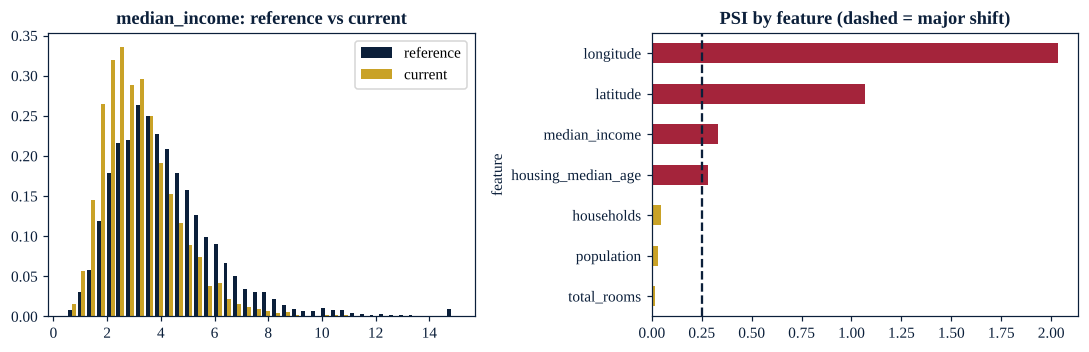

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
ref_tr, ref_te = train_test_split(reference, test_size=0.2, random_state=SEED)
reg = HistGradientBoostingRegressor(random_state=SEED).fit(ref_tr[feats], ref_tr.median_house_value)
perf = pd.Series({"RMSE on reference hold-out": root_mean_squared_error(ref_te.median_house_value, reg.predict(ref_te[feats])),
                  "RMSE on drifted 'current' data": root_mean_squared_error(current.median_house_value, reg.predict(current[feats]))}).round(0)
print(perf.to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].hist([reference.median_income, current.median_income], bins=40, color=[NAVY, GOLD], label=["reference", "current"], density=True)
ax[0].set_title("median_income: reference vs current"); ax[0].legend()
drift.set_index("feature").PSI.sort_values().plot.barh(ax=ax[1], color=[GOLD if v < 0.25 else "#A4243B" for v in drift.set_index("feature").PSI.sort_values()])
ax[1].axvline(0.25, color=NAVY, ls="--"); ax[1].set_title("PSI by feature (dashed = major shift)")
plt.tight_layout(); plt.savefig(FIG/"s6_drift.png", bbox_inches="tight"); plt.show()

When PSI crosses your threshold, the pipeline should **alert, investigate, and retrain** — and the registry keeps the old version for rollback.

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 27 — Responsible AI: fairness, red-teaming, law

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">UCI Adult (fairness) + TruthfulQA (red-teaming)</span>
**Skills:** <span style="color:#6A3D9A">Fairlearn, bias mitigation, red-team playbooks, AI governance literacy</span>

In [7]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, equalized_odds_difference
cols = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation","relationship","race","sex",
        "capital_gain","capital_loss","hours_per_week","native_country","income"]
adult = pd.read_csv(fetch("https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv", "adult-all.csv"),
                    header=None, names=cols, na_values="?", skipinitialspace=True).fillna("Unknown").drop_duplicates()
ya = (adult.pop("income") == ">50K").astype(int); sex = adult["sex"]
num_a = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]; cat_a = ["workclass", "marital_status", "occupation", "relationship"]
Xa_tr, Xa_te, ya_tr, ya_te, s_tr, s_te = train_test_split(adult[num_a + cat_a], ya, sex, test_size=0.3, stratify=ya, random_state=SEED)
prep_a = ColumnTransformer([("n", StandardScaler(), num_a), ("c", OneHotEncoder(handle_unknown="ignore"), cat_a)])
base = Pipeline([("p", prep_a), ("m", LogisticRegression(max_iter=3000))]).fit(Xa_tr, ya_tr)
pred = base.predict(Xa_te)
mf = MetricFrame(metrics={"selection rate": selection_rate, "TPR (recall)": true_positive_rate, "FPR": false_positive_rate, "accuracy": accuracy_score},
                 y_true=ya_te, y_pred=pred, sensitive_features=s_te)
print("Note: 'sex' is NOT a model input — the model still treats groups differently through correlated features.\n")
mf.by_group.round(3)

Note: 'sex' is NOT a model input — the model still treats groups differently through correlated features.



,selection rate,TPR (recall),FPR,accuracy
sex,,,,
Female,0.073,0.494,0.020,0.925
Male,0.262,0.631,0.101,0.817


In [8]:
def fairness_row(name, y_pred):
    return {"method": name, "accuracy": accuracy_score(ya_te, y_pred),
            "demographic parity diff": demographic_parity_difference(ya_te, y_pred, sensitive_features=s_te),
            "equalized odds diff": equalized_odds_difference(ya_te, y_pred, sensitive_features=s_te)}
rows = [fairness_row("Baseline", pred)]

# Mitigation 1 — reweighing (pre-processing): weight each (group, label) cell so group and label look independent
w = pd.Series(1.0, index=Xa_tr.index)
for g in s_tr.unique():
    for lab in [0, 1]:
        m = (s_tr == g) & (ya_tr == lab); w[m] = (s_tr == g).mean() * (ya_tr == lab).mean() / m.mean()
rew = Pipeline([("p", prep_a), ("m", LogisticRegression(max_iter=3000))]).fit(Xa_tr, ya_tr, m__sample_weight=w.values)
rows.append(fairness_row("Reweighing", rew.predict(Xa_te)))

# Mitigation 2 — Fairlearn ThresholdOptimizer (post-processing) for equalized odds
from fairlearn.postprocessing import ThresholdOptimizer
to = ThresholdOptimizer(estimator=base, constraints="equalized_odds", prefit=True, predict_method="predict_proba")
to.fit(Xa_tr, ya_tr, sensitive_features=s_tr)
rows.append(fairness_row("Equalized-odds thresholds", to.predict(Xa_te, sensitive_features=s_te, random_state=SEED)))
fair = pd.DataFrame(rows).round(3); fair

,method,accuracy,demographic parity diff,equalized odds diff
0,Baseline,0.854,0.189,0.137
1,Reweighing,0.849,0.102,0.082
2,Equalized-odds thresholds,0.838,0.097,0.055


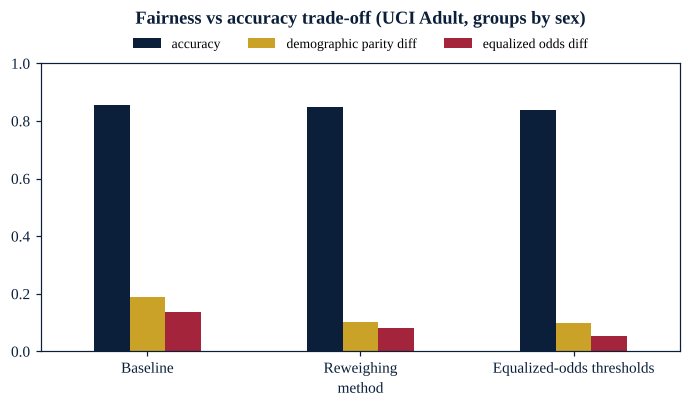

In [9]:
ax = fair.set_index("method")[["accuracy", "demographic parity diff", "equalized odds diff"]].plot.bar(figsize=(7.5, 3.4), color=[NAVY, GOLD, "#A4243B"], rot=0)
ax.set_title("Fairness vs accuracy trade-off (UCI Adult, groups by sex)", pad=26); ax.set_ylim(0, 1)
plt.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=9)
plt.savefig(FIG/"s6_fairness.png", bbox_inches="tight"); plt.show()

**No free lunch:** mitigation lowers the gap between groups, usually at a small cost in accuracy. *Which* fairness
definition fits depends on the decision (loans? hiring? medical screening?) — that is a human and legal choice,
documented in your audit, not a default setting.

In [10]:
# Red-teaming: probe a naive 'answer by nearest stored statement' system with TruthfulQA, by category
import re
from rank_bm25 import BM25Okapi
tqa = pd.read_csv(fetch("https://raw.githubusercontent.com/sylinrl/TruthfulQA/main/TruthfulQA.csv", "TruthfulQA.csv"))
store = tqa["Best Answer"].tolist() + tqa["Best Incorrect Answer"].tolist()
tk = lambda s: re.findall(r"[a-z0-9]+", s.lower()); bm = BM25Okapi([tk(x) for x in store])
top = [int(np.argmax(bm.get_scores(tk(q)))) for q in tqa.Question]
tqa["system says the misconception"] = [t == len(tqa) + i for i, t in enumerate(top)]
redteam = tqa.groupby("Category")["system says the misconception"].agg(["mean", "count"]).query("count >= 15").sort_values("mean", ascending=False)
print(f"Overall: the system repeats the question's own misconception {tqa['system says the misconception'].mean():.1%} of the time.")
redteam.head(8).round(3)

Overall: the system repeats the question's own misconception 47.1% of the time.


,mean,count
Category,,
Nutrition,0.875,16
Psychology,0.737,19
Myths and Fairytales,0.619,21
Fiction,0.567,30
Misquotations,0.562,16
Indexical Error: Other,0.556,18
History,0.542,24
Paranormal,0.538,26


**Red-team playbook (keep it in `docs/redteam.md`):** misconceptions · prompt injection inside documents ·
requests for personal data · jailbreak role-play · harmful advice · bias probes with swapped names/genders ·
over-confident answers to unanswerable questions. Log each probe, the output, severity and the fix.

**AI law basics (not legal advice):**
* **EU AI Act** — risk tiers: *unacceptable* (banned), *high-risk* (e.g. hiring, credit, education scoring — strict
  obligations: risk management, data governance, human oversight, logging), *limited* (transparency, e.g. telling users
  they talk to AI), *minimal*.
* **India DPDP Act 2023** — personal data needs a lawful purpose and consent; individuals (*data principals*) have
  rights to access, correction and erasure; organisations (*data fiduciaries*) must protect data and report breaches;
  enforced by the Data Protection Board of India.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 28 — Capstone hardening: automated readiness audit

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Your capstone repository</span>
**Skills:** <span style="color:#6A3D9A">Testing, monitoring, audit documentation, deployment readiness</span>

In [11]:
(PROJ / "README.md").write_text("# Churn Intelligence API\n## Problem\n## Dataset\n## Method\n## Results\n## How to run\n## Limitations & ethics\n## AI-assistant use\n")
(PROJ / "MODEL_CARD.md").write_text(f"# Model card\nChurn logistic regression v{meta['version']}, ROC-AUC {meta['metrics']['roc_auc']}.\n")
CHECKS = {
    "README with required sections": lambda p: all(s in (p / "README.md").read_text() for s in ["## Problem", "## Dataset", "## Results", "## How to run", "## Limitations"]) if (p / "README.md").exists() else False,
    "requirements.txt": lambda p: (p / "requirements.txt").exists(),
    "automated tests": lambda p: any((p / "tests").glob("test_*.py")),
    "tests pass": lambda p: subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], cwd=p, capture_output=True).returncode == 0,
    "Dockerfile": lambda p: (p / "Dockerfile").exists(),
    "CI workflow": lambda p: any((p / ".github" / "workflows").glob("*.yml")),
    "model card": lambda p: (p / "MODEL_CARD.md").exists(),
    "fairness / safety audit": lambda p: (p / "docs" / "audit.md").exists(),
    "LICENSE": lambda p: (p / "LICENSE").exists(),
    "no secrets committed": lambda p: not any(re.search(r"(api[_-]?key|secret|password)\s*=\s*['\"][^'\"]{8,}", f.read_text(errors="ignore"), re.I)
                                             for f in p.rglob("*.py")),
}
audit = pd.DataFrame([{"check": k, "pass": bool(fn(PROJ))} for k, fn in CHECKS.items()])
print(f"Readiness score: {audit['pass'].sum()}/{len(audit)}"); audit

Readiness score: 8/10


,check,pass
0,README with required sections,True
1,requirements.txt,True
2,automated tests,True
3,tests pass,True
4,Dockerfile,True
5,CI workflow,True
6,model card,True
7,fairness / safety audit,False
8,LICENSE,False
9,no secrets committed,True


Two red rows = two tickets before Demo Day: write `docs/audit.md` (fairness + red-team results) and add a `LICENSE`. Re-run the audit until it is all green.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 29 — Demo Day: a 7-minute pitch built from real results

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Your capstone results</span>
**Skills:** <span style="color:#6A3D9A">Product thinking, technical pitch, handling hard questions</span>

In [12]:
pitch = [("0:00–0:45", "Hook", "Telecoms lose about one in four customers here; each loss costs months of revenue."),
         ("0:45–1:45", "Problem & user", "Retention teams call customers at random; they need a ranked call list."),
         ("1:45–3:15", "Live demo", "POST /predict for a new month-to-month customer -> high risk, with reasons."),
         ("3:15–4:30", "Evidence", f"ROC-AUC {meta['metrics']['roc_auc']} on held-out data; {audit['pass'].sum()}/{len(audit)} readiness checks; drift monitor in place."),
         ("4:30–5:30", "Responsibility", "Fairness audit, model card, human decides who gets the offer."),
         ("5:30–6:30", "What's next", "A/B test retention offers; retrain monthly when PSI > 0.25."),
         ("6:30–7:00", "Ask", "Pilot with one retention team for 4 weeks.")]
pd.DataFrame(pitch, columns=["time", "slide", "say this"])

,time,slide,say this
0,0:00–0:45,Hook,Telecoms lose about one in four customers here...
1,0:45–1:45,Problem & user,Retention teams call customers at random; they...
2,1:45–3:15,Live demo,POST /predict for a new month-to-month custome...
3,3:15–4:30,Evidence,ROC-AUC 0.8438 on held-out data; 8/10 readines...
4,4:30–5:30,Responsibility,"Fairness audit, model card, human decides who ..."
5,5:30–6:30,What's next,A/B test retention offers; retrain monthly whe...
6,6:30–7:00,Ask,Pilot with one retention team for 4 weeks.


**Panel questions to rehearse:** *What happens when the data drifts? How do you know it's fair? What is the cost of a
false positive vs a false negative? Why this model and not a bigger one? What would make you switch it off?*

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 30 — Career Lab: mock interviews, skills radar, 90-day plan

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Interview question bank</span>
**Skills:** <span style="color:#6A3D9A">Interview performance, portfolio positioning, founder basics</span>

In [13]:
BANK = {
 "ML fundamentals": ["Explain the bias–variance trade-off with an example from your P1.", "Why can accuracy be misleading? What would you report instead?",
                     "How do you detect and prevent data leakage?"],
 "Deep learning": ["Walk through one training step: forward, loss, backward, optimiser.", "Why did the CNN collapse under noise in P2 while the ViT did not? How would you fix it?"],
 "LLMs & agents": ["Explain self-attention and the causal mask.", "When is LoRA better than full fine-tuning?", "How do you stop a RAG system from hallucinating?",
                   "Design an evaluation harness for a tool-using agent."],
 "ML system design": ["Design a churn-prediction service for 10 million customers: data, training, serving, monitoring.",
                      "Design a document Q&A system for a university with 50,000 PDFs."],
 "Responsible AI": ["Your model shows a demographic parity gap of 0.15. What do you do?", "Which EU AI Act risk tier is a CV-screening tool, and what follows?"],
 "Behavioural": ["Tell me about a model that failed and what you learned.", "Describe a time you disagreed with a teammate about a technical choice."],
}
rng = np.random.default_rng(SEED)
print("MOCK INTERVIEW — 6 questions, 5 minutes each\n")
for i, (area, qs) in enumerate(BANK.items(), 1): print(f"{i}. [{area}] {qs[rng.integers(len(qs))]}")

MOCK INTERVIEW — 6 questions, 5 minutes each

1. [ML fundamentals] Explain the bias–variance trade-off with an example from your P1.
2. [Deep learning] Why did the CNN collapse under noise in P2 while the ViT did not? How would you fix it?
3. [LLMs & agents] How do you stop a RAG system from hallucinating?
4. [ML system design] Design a churn-prediction service for 10 million customers: data, training, serving, monitoring.
5. [Responsible AI] Your model shows a demographic parity gap of 0.15. What do you do?
6. [Behavioural] Describe a time you disagreed with a teammate about a technical choice.


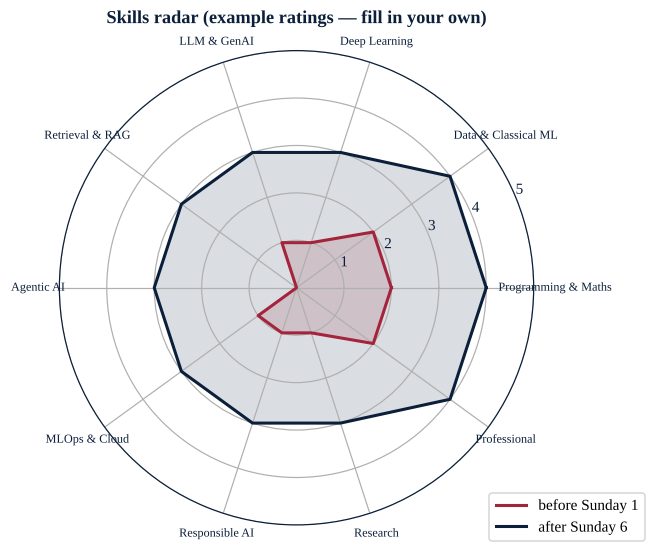

In [14]:
# Skills self-assessment radar: replace the example scores (0–5) with your own honest ratings
skills = ["Programming & Maths", "Data & Classical ML", "Deep Learning", "LLM & GenAI", "Retrieval & RAG",
          "Agentic AI", "MLOps & Cloud", "Responsible AI", "Research", "Professional"]
before = [2, 2, 1, 1, 0, 0, 1, 1, 1, 2]; after = [4, 4, 3, 3, 3, 3, 3, 3, 3, 4]      # EXAMPLE values
ang = np.linspace(0, 2 * np.pi, len(skills), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(5.6, 5.6)); ax = plt.subplot(polar=True)
for vals, col, lab in [(before, "#A4243B", "before Sunday 1"), (after, NAVY, "after Sunday 6")]:
    v = vals + vals[:1]; ax.plot(ang, v, color=col, lw=2, label=lab); ax.fill(ang, v, color=col, alpha=0.15)
ax.set_xticks(ang[:-1], skills, fontsize=8); ax.set_yticks([1, 2, 3, 4, 5]); ax.set_ylim(0, 5)
ax.set_title("Skills radar (example ratings — fill in your own)", pad=18); ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05))
plt.savefig(FIG/"s6_radar.png", bbox_inches="tight"); plt.show()

**90-day plan:** days 1–30 polish all six repos and write one blog post per project · days 31–60 put the capstone in
front of real users and enter one competition · days 61–90 apply to 30+ targeted roles with referrals and keep doing
mock interviews.

> **Honest note:** this course gives you a strong, evidence-backed start. Offers come from what you keep building after it.

---
<div style="background:#FFF3E0;border-left:6px solid #FF9933;padding:12px 16px;border-radius:6px">
<b>GitHub submission — by 18:00 local time today</b><br>
1. Copy this notebook into <code>P6-capstone/notebooks/</code> of your portfolio repo.<br>
2. Move reusable functions into <code>P6-capstone/src/</code>, save plots into <code>results/</code>.<br>
3. Update the project README (problem, dataset, method, results, how to run, limitations &amp; ethics, AI-assistant use).<br>
4. <code>git push origin main</code> → <code>git tag -a sunday-6 -m "Sunday 6 submission"</code> → <code>git push origin sunday-6</code><br>
5. Create a GitHub Release from the tag and submit the link on the AlgoProfessor form.
</div>